# **Assignment 6**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [1]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
from sklearn.kernel_ridge import KernelRidge
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from tabulate import tabulate  
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import accuracy_score


In [2]:
# Load the dataset
df = pd.read_csv('datasets/data.csv')

X = df.drop(['diagnosis', 'id', 'Unnamed: 32'], axis=1)  # Features (also drop id column and Unnamed cuz na)
y = df['diagnosis'].map({'M': 1, 'B': 0})  # make into 0 or 1 so there are no strings

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.fillna(X_train.mean(), inplace=True)
X_test.fillna(X_train.mean(), inplace=True)


# Normalize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Defining the parameters
param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'C': [0.001, 0.01, 0.1, 1, 10 ],  
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1, 10]  
}

# Perform Grid Search
grid_search = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

# Get all results from grid search
results = grid_search.cv_results_

# Store the relevant information for table later
performance_metrics = []

for mean_score, std_score, params in zip(results['mean_test_score'], results['std_test_score'], results['params']):
    performance_metrics.append({
        "Kernel": params['kernel'],
        "C": params['C'],
        "Gamma": params['gamma'],
        "Mean Test Score (Accuracy)": mean_score,
        "Std Test Score": std_score
    })


metrics_df = pd.DataFrame(performance_metrics)
print(tabulate(metrics_df, headers='keys', tablefmt='pretty', showindex=False))

# Get best parameters and model
print("\nBest parameters found: ", grid_search.best_params_)
best_model = grid_search.best_estimator_

# Evaluate on test data
test_accuracy = best_model.score(X_test, y_test)
print(f"Test accuracy: {test_accuracy:.4f}")


+---------+-------+-------+----------------------------+----------------------+
| Kernel  |   C   | Gamma | Mean Test Score (Accuracy) |    Std Test Score    |
+---------+-------+-------+----------------------------+----------------------+
| linear  | 0.001 | scale |     0.9340659340659341     | 0.020850182374736563 |
|  poly   | 0.001 | scale |     0.6373626373626373     | 0.009828870230768321 |
|   rbf   | 0.001 | scale |     0.6285714285714286     | 0.004395604395604381 |
| sigmoid | 0.001 | scale |     0.6285714285714286     | 0.004395604395604381 |
| linear  | 0.001 | auto  |     0.9340659340659341     | 0.020850182374736563 |
|  poly   | 0.001 | auto  |     0.6373626373626373     | 0.009828870230768321 |
|   rbf   | 0.001 | auto  |     0.6285714285714286     | 0.004395604395604381 |
| sigmoid | 0.001 | auto  |     0.6285714285714286     | 0.004395604395604381 |
| linear  | 0.001 | 0.001 |     0.9340659340659341     | 0.020850182374736563 |
|  poly   | 0.001 | 0.001 |     0.628571

For simpler overview let's also check the smaller tables:

In [14]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']

results_kernel = []

for kernel in kernels:
    model = SVC(kernel=kernel, C=1, gamma='scale')
    model.fit(X_train, y_train)
    
    # Train accuracy
    y_pred_train = model.predict(X_train)
    train_accuracy = accuracy_score(y_train, y_pred_train)
    
    # Test accuracy
    y_pred_test = model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    
    results_kernel.append([kernel, train_accuracy, test_accuracy])

headers_kernel = ["Kernel", "Train Accuracy", "Test Accuracy"]
print(tabulate(results_kernel, headers=headers_kernel, tablefmt="grid"))


+----------+------------------+-----------------+
| Kernel   |   Train Accuracy |   Test Accuracy |
+==========+==================+=================+
| linear   |         0.986813 |        0.95614  |
+----------+------------------+-----------------+
| poly     |         0.914286 |        0.868421 |
+----------+------------------+-----------------+
| rbf      |         0.989011 |        0.982456 |
+----------+------------------+-----------------+
| sigmoid  |         0.949451 |        0.95614  |
+----------+------------------+-----------------+


In [ ]:
C_values = [0.001, 0.01, 0.1, 1, 10]
kernel_values = ['rbf']  # Fixed value for kernel
gamma_values = ['scale']  # Fixed value for gamma

results_C = []

for C in C_values:
    model = SVC(kernel=kernel_values[0], C=C, gamma=gamma_values[0])
    model.fit(X_train, y_train)
    
    # Train accuracy
    y_pred_train = model.predict(X_train)
    train_accuracy = accuracy_score(y_train, y_pred_train)
    
    # Test accuracy
    y_pred_test = model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    
    results_C.append([C, train_accuracy, test_accuracy])

headers_C = ["C Value", "Train Accuracy", "Test Accuracy"]
print(tabulate(results_C, headers=headers_C, tablefmt="grid"))


+-----------+------------------+-----------------+
|   C Value |   Train Accuracy |   Test Accuracy |
+===========+==================+=================+
|     0.001 |         0.628571 |        0.622807 |
+-----------+------------------+-----------------+
|     0.01  |         0.628571 |        0.622807 |
+-----------+------------------+-----------------+
|     0.1   |         0.956044 |        0.947368 |
+-----------+------------------+-----------------+
|     1     |         0.989011 |        0.982456 |
+-----------+------------------+-----------------+
|    10     |         0.993407 |        0.973684 |
+-----------+------------------+-----------------+


In [ ]:
gamma_values = ['scale', 'auto', 0.001, 0.01, 0.1, 1, 10]
kernel_values = ['rbf']  # Fixed value for kernel
C_values = [1]  # Fixed value for C

results_gamma = []

for gamma in gamma_values:
    model = SVC(kernel=kernel_values[0], C=C_values[0], gamma=gamma)
    model.fit(X_train, y_train)
    
    # Train accuracy
    y_pred_train = model.predict(X_train)
    train_accuracy = accuracy_score(y_train, y_pred_train)
    
    # Test accuracy
    y_pred_test = model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    
    results_gamma.append([gamma, train_accuracy, test_accuracy])

headers_gamma = ["Gamma Value", "Train Accuracy", "Test Accuracy"]
print(tabulate(results_gamma, headers=headers_gamma, tablefmt="grid"))


+---------------+------------------+-----------------+
| Gamma Value   |   Train Accuracy |   Test Accuracy |
+===============+==================+=================+
| scale         |         0.989011 |        0.982456 |
+---------------+------------------+-----------------+
| auto          |         0.989011 |        0.982456 |
+---------------+------------------+-----------------+
| 0.001         |         0.947253 |        0.964912 |
+---------------+------------------+-----------------+
| 0.01          |         0.973626 |        0.964912 |
+---------------+------------------+-----------------+
| 0.1           |         0.993407 |        0.964912 |
+---------------+------------------+-----------------+
| 1             |         1        |        0.631579 |
+---------------+------------------+-----------------+
| 10            |         1        |        0.622807 |
+---------------+------------------+-----------------+


From the output we see the best parameters found are rbf kernel, c = 1 and gamma = 'scale'

Following you can also take a look at the plots for each kernel

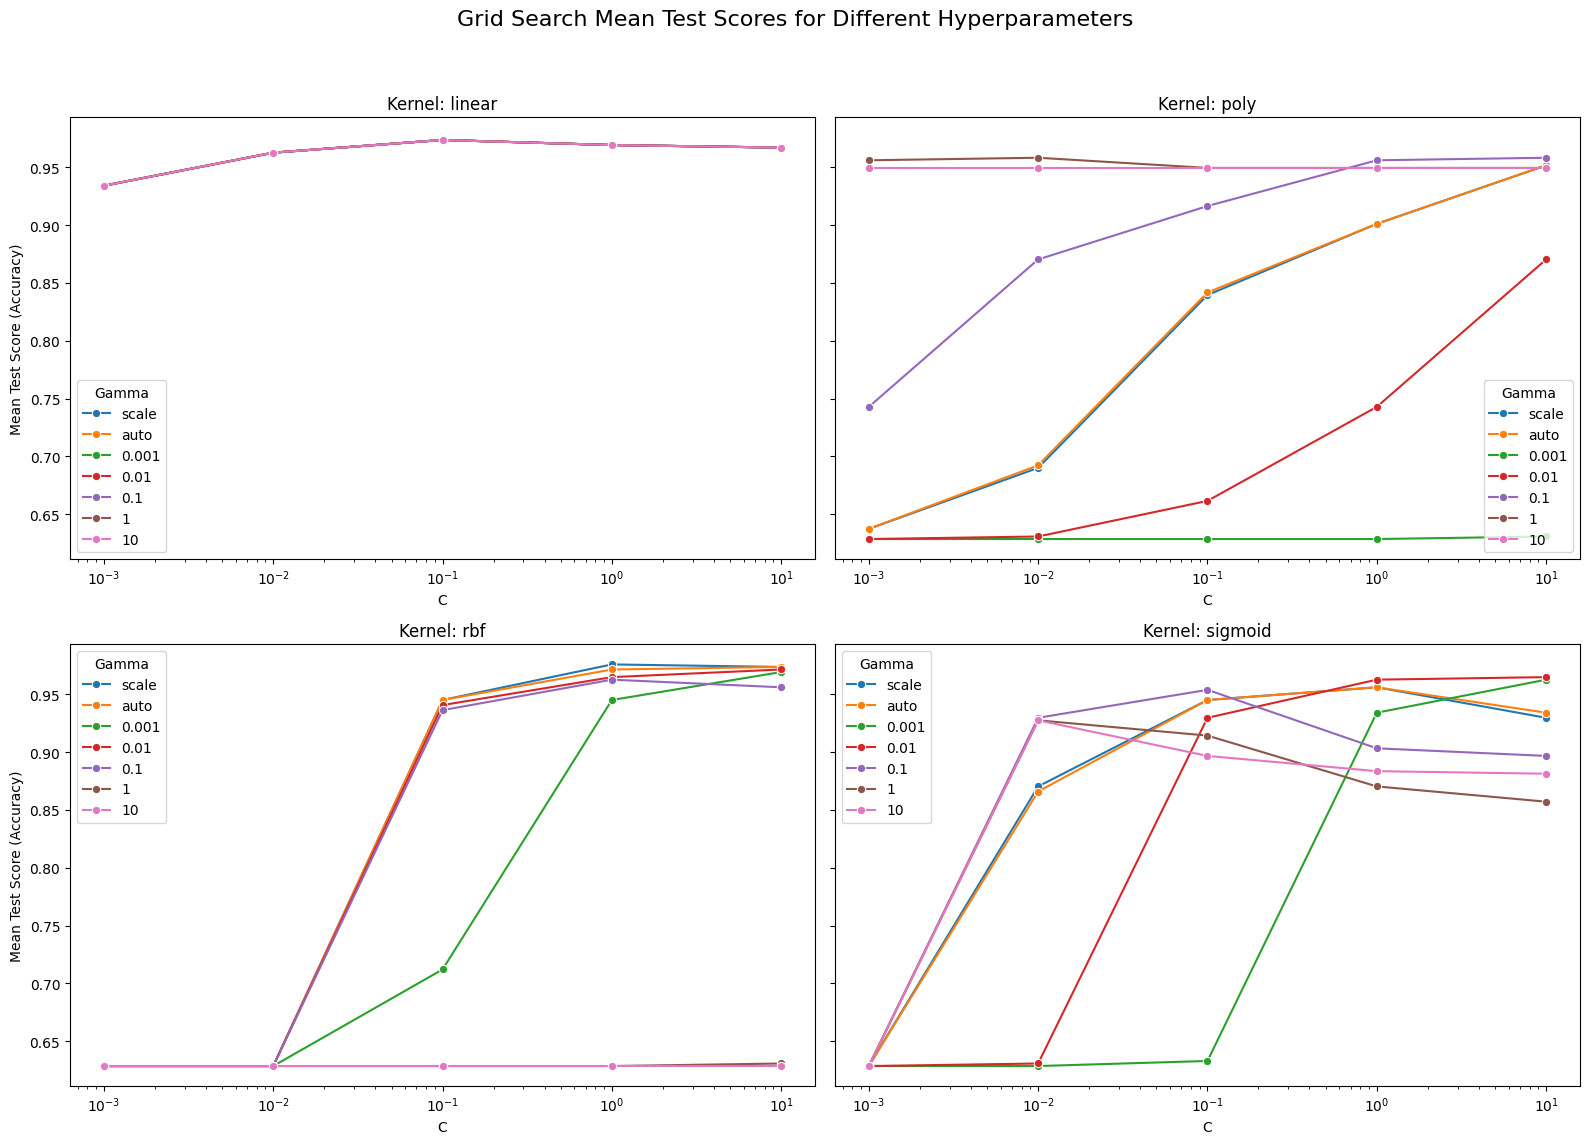

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_df = pd.DataFrame(performance_metrics)

metrics_df = metrics_df.drop_duplicates(subset=['C', 'Gamma', 'Kernel'])
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
axes = axes.flatten()

# Plot each kernel type in separate subplots
kernels = metrics_df['Kernel'].unique()
for ax, kernel in zip(axes, kernels):
    subset = metrics_df[metrics_df['Kernel'] == kernel]
    sns.lineplot(data=subset, x='C', y='Mean Test Score (Accuracy)', hue='Gamma', marker='o', ax=ax)
    ax.set_title(f'Kernel: {kernel}')
    ax.set_xscale('log')
    ax.set_ylabel('Mean Test Score (Accuracy)')
    ax.set_xlabel('C')

fig.suptitle('Grid Search Mean Test Scores for Different Hyperparameters', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


## My implementation

In [ ]:
# kernel functions
def linear_kernel(X1, X2):
    return np.dot(X1, X2.T)

def rbf_kernel(X1, X2, gamma=1.0):
    squared_distances  = np.sum(X1**2, axis=1).reshape(-1, 1) + np.sum(X2**2, axis=1) - 2 * np.dot(X1, X2.T)
    return np.exp(-gamma * squared_distances )

def poly_kernel(X1, X2, degree=3, c0=1):
    return (np.dot(X1, X2.T) + c0)**degree

# Kernel Ridge Regression model
class KernelRidge:
    def __init__(self, kernel='linear', C=1.0, gamma=None, degree=3, c0=1):
        self.kernel = kernel
        self.C = C
        self.gamma = gamma if kernel in ['rbf', 'poly'] else None
        self.degree = degree if kernel == 'poly' else None
        self.c0 = c0 if kernel == 'poly' else None
        self.alpha_matrix = None
        self.X_train = None
        self.kernel_matrix = None
    
    def fit(self, X_train, y_train):
        self.X_train = X_train
        # diff based on kernel choice
        if self.kernel == 'linear':
            self.kernel_matrix = linear_kernel(X_train, X_train)
        elif self.kernel == 'rbf':
            self.kernel_matrix = rbf_kernel(X_train, X_train, gamma=self.gamma)
        elif self.kernel == 'poly':
            self.kernel_matrix = poly_kernel(X_train, X_train, degree=self.degree, c0=self.c0)
        else:
            raise ValueError("Unknown kernel")

        # Regularized kernel matrix
        self.alpha_matrix = np.linalg.inv(self.kernel_matrix + self.C * np.identity(len(X_train))).dot(y_train)
    
    def predict(self, X_test):
        # Compute the kernel matrix for test data and training data
        if self.kernel == 'linear':
            K_test = linear_kernel(X_test, self.X_train)
        elif self.kernel == 'rbf':
            K_test = rbf_kernel(X_test, self.X_train, gamma=self.gamma)
        elif self.kernel == 'poly':
            K_test = poly_kernel(X_test, self.X_train, degree=self.degree, c0=self.c0)
        
        return np.dot(K_test, self.alpha_matrix)  # Predicted values
    
    def score(self, X_test, y_test):
        # MSE
        y_pred = self.predict(X_test)
        return np.mean((y_pred - y_test)**2)

In [ ]:
kernels = ['linear', 'rbf', 'poly']
Cs = [0.001, 0.01, 0.1, 1, 10] 
gammas = [0.001, 0.01, 0.1, 1, 10]  

# Initialize a dictionary to store the performance metrics for each kernel
performance_metrics = []

# Train and test Kernel Ridge models with different kernels and parameters
for kernel in kernels:
    for c in Cs:
        for gamma in gammas:
            model = KernelRidge(kernel=kernel, C=c, gamma=gamma if kernel in ['rbf', 'poly'] else None)
            model.fit(X_train, y_train)
            
            # Calculate MSE and MAE
            mse = model.score(X_test, y_test)  # Evaluate on test set
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            
            # Store the performance metrics
            performance_metrics.append({
                "Kernel": kernel,
                "Alpha": c,
                "Gamma": gamma, 
                "MSE": mse,
                "MAE": mae
            })

metrics_df = pd.DataFrame(performance_metrics)

print(tabulate(metrics_df, headers='keys', tablefmt='pretty', showindex=False))



+--------+-------+-------+----------------------+---------------------+
| Kernel | Alpha | Gamma |         MSE          |         MAE         |
+--------+-------+-------+----------------------+---------------------+
| linear | 0.001 | 0.001 |  0.1802407139577975  | 0.3588958106767201  |
| linear | 0.001 | 0.01  |  0.1802407139577975  | 0.3588958106767201  |
| linear | 0.001 |  0.1  |  0.1802407139577975  | 0.3588958106767201  |
| linear | 0.001 |  1.0  |  0.1802407139577975  | 0.3588958106767201  |
| linear | 0.001 | 10.0  |  0.1802407139577975  | 0.3588958106767201  |
| linear | 0.01  | 0.001 | 0.18038171744210182  |  0.359049783454835  |
| linear | 0.01  | 0.01  | 0.18038171744210182  |  0.359049783454835  |
| linear | 0.01  |  0.1  | 0.18038171744210182  |  0.359049783454835  |
| linear | 0.01  |  1.0  | 0.18038171744210182  |  0.359049783454835  |
| linear | 0.01  | 10.0  | 0.18038171744210182  |  0.359049783454835  |
| linear |  0.1  | 0.001 | 0.18072176824627534  | 0.359315759272

Here are smaller tables for simpler review

In [ ]:
# Initialize a list to store performance metrics for each kernel
performance_kernel = []

# Train and test Kernel Ridge models with different kernels
for kernel in kernels:
        model = KernelRidge(kernel=kernel, C=0.1, gamma=0.1 if kernel in ['rbf', 'poly'] else None)
        model.fit(X_train, y_train)
        
        # Calculate MSE and MAE
        mse = model.score(X_test, y_test)
        y_pred = model.predict(X_test)
        mae = mean_absolute_error(y_test, y_pred)
        
        # Store the performance metrics
        performance_kernel.append({
            "Kernel": kernel,
            "MSE": mse,
            "MAE": mae,
        })


metrics_kernel_df = pd.DataFrame(performance_kernel)

print("Performance by Kernel:")
print(tabulate(metrics_kernel_df, headers='keys', tablefmt='pretty', showindex=False))


Performance by Kernel:
+--------+---------------------+---------------------+
| Kernel |         MSE         |         MAE         |
+--------+---------------------+---------------------+
| linear | 0.18072176824627534 | 0.35931575927251974 |
|  rbf   | 0.08467975599461355 | 0.17473467710039997 |
|  poly  |  2.04186361236547   | 0.6405337993850965  |
+--------+---------------------+---------------------+


We see that poly model performes much worse then the other 2. RBF is the best

In [ ]:
# Initialize a list to store performance metrics for each gamma value
performance_gamma = []

# Train and test Kernel Ridge models with different gamma values
for gamma in gammas:

    model = KernelRidge(kernel='rbf', C=0.1, gamma=gamma)
    model.fit(X_train, y_train)

    # Calculate MSE and MAE
    mse = model.score(X_test, y_test)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    # Store the performance metrics
    performance_gamma.append({
        "Gamma": gamma,
        "MSE": mse,
        "MAE": mae
    })

metrics_gamma_df = pd.DataFrame(performance_gamma)

print("\nPerformance by Gamma:")
print(tabulate(metrics_gamma_df, headers='keys', tablefmt='pretty', showindex=False))



Performance by Gamma:
+-------+---------------------+---------------------+
| Gamma |         MSE         |         MAE         |
+-------+---------------------+---------------------+
| 0.001 | 0.05032031038162031 | 0.18148371111492784 |
| 0.01  | 0.03708491762555046 | 0.1408390768894299  |
|  0.1  | 0.08467975599461355 | 0.17473467710039997 |
|  1.0  | 0.3619992905050682  | 0.3714935094105434  |
| 10.0  | 0.37719289535910516 | 0.3771929389344375  |
+-------+---------------------+---------------------+


In [ ]:
performance_C = []

# Train and test Kernel Ridge models with different C values
for c in Cs:
    model = KernelRidge(kernel='rbf', C=c, gamma=0.01)
    model.fit(X_train, y_train)
    
    # Calculate MSE and MAE
    mse = model.score(X_test, y_test)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    
    # Store the performance metrics
    performance_C.append({
        "C": c,
        "MSE": mse,
        "MAE": mae
    })

metrics_C_df = pd.DataFrame(performance_C)

print("\nPerformance by C:")
print(tabulate(metrics_C_df, headers='keys', tablefmt='pretty', showindex=False))



Performance by C:
+-------+----------------------+---------------------+
|   C   |         MSE          |         MAE         |
+-------+----------------------+---------------------+
| 0.001 | 0.05956227979936828  | 0.17238645035743683 |
| 0.01  | 0.039622476850845155 | 0.14330320150315998 |
|  0.1  | 0.03708491762555046  | 0.1408390768894299  |
|  1.0  | 0.03925304194916366  | 0.14785037083405853 |
| 10.0  | 0.05565048149131206  | 0.18783901413533896 |
+-------+----------------------+---------------------+


From the tables we see that best performance is with kernel rbf, gamma 0.01 and C 0.1.

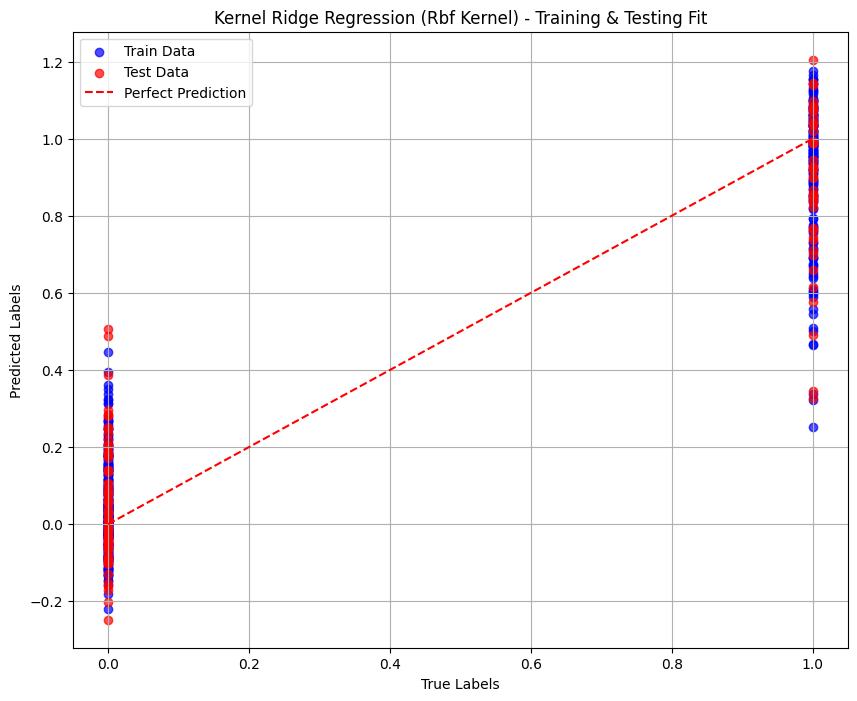

In [ ]:
# The best model which we established in previous step
model = KernelRidge(kernel='rbf', C=0.1, gamma=0.01)
model.fit(X_train, y_train)

# Make predictions on both training and test data
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


plt.figure(figsize=(10, 8))
plt.scatter(y_train, y_train_pred, color='blue', label="Train Data", alpha=0.7)
plt.scatter(y_test, y_test_pred, color='red', label="Test Data", alpha=0.7)
plt.plot([min(np.min(y_train), np.min(y_test)), max(np.max(y_train), np.max(y_test))], 
         [min(np.min(y_train), np.min(y_test)), max(np.max(y_train), np.max(y_test))], '--', color='red', label='Perfect Prediction')

plt.xlabel('True Labels')
plt.ylabel('Predicted Labels')
plt.title(f"Kernel Ridge Regression ({model.kernel.capitalize()} Kernel) - Training & Testing Fit")
plt.legend(loc='upper left')


plt.grid(True)
plt.show()


Ridge regression is a linear model, which means it assumes a linear relationship between the input features and the target variable. In this case, since the target variable is binary (1 or 0), so the predictions made by ridge regression aren't ideal for classification. In these cases we would need to establish a threshold. (like here 0.5)